# LM20 Lab — Estimation Theory and Maximum Likelihood

Companion notebook to **From Calculus to Kelly, LM20**. It rebuilds the module's exhibits and computational examples, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's returns, $T$, $\tau$, $A$, the guard and its exact check, the divisors of NumPy and Polars |
| 2 | Sampling distributions: Exhibit 2 (experiments 1 and 4) and Example 1 |
| 3 | The standard error of a mean: Example 2, Example 3, Exhibit 3 and Exhibit 5 |
| 4 | Confidence intervals: Example 4 and Exhibit 4 (experiment 2) |
| 5 | Maximum likelihood: Example 5 (0050 rebuilt), Example 6 with a central-difference Hessian, Exhibit 6 and Exhibit 7 |
| 6 | Information and the delta method: Example 7, Example 8, Example 9 and Exhibit 8 |
| 7 | The Hill estimator: Example 10 and Exhibit 9 |
| 8 | Practice problems 6 to 11, and an extension: the Kelly fraction in each limit regime |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv`, the closes of the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`). It also holds LM4's `0050_daily_raw.csv`, `0050_dividends.csv` and `00631L_daily_raw.csv` (`TaiwanStockPrice`, `TaiwanStockDividendResult`), and LM16's `sectors_close_raw.csv` and `sectors_close_repairs.csv` (`TaiwanStockPrice` sector indices, with repairs from `TaiwanStockEvery5SecondsIndex`). The notebook reads nothing outside `data/`. On FinMind's free plan the repair values are missing; Problem 6 then drops the listed closes, and its numbers differ from the module's (the cell says so).

**Conventions (as in the module).** TR23: $T=5{,}849$ simple daily returns from 3 January 2003 to 8 October 2026; log returns $r_t=\ln(1+R_t)$ enter every sum. The standard deviation $s$ and the moments divide by $T$ (`ddof=0`), and $s_{\mathrm u}$ by $T-1$ (`ddof=1`); pass `ddof` every time. The sessions a year are $A=T/\tau$, with $\tau$ the calendar days from the first to the last close over 365.25. Intervals are estimate ± 1.96 standard errors.

Counts use the guard `1e-12` and are checked exactly with `Fraction` on the two-decimal closes. Each simulated experiment $e$ creates `np.random.default_rng([e, 20261011])` once. Quantiles of simulated values use `method="inverted_cdf"`. Everything is in-sample and assumes independent, identically distributed days; simulations are models.

In [1]:
from fractions import Fraction
from math import log, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy import optimize, stats

DATA = Path("data")
EPS = 1e-12                       # the guard at every edge: two-decimal closes make round returns exact ties
Z = 1.96
SEED = 20261011
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def moments(x):
    # mean, s (divisor n), third and fourth central moments (divisor n)
    xc = x - x.mean()
    return x.mean(), x.std(ddof=0), (xc**3).mean(), (xc**4).mean()

## Part 1 — Data

TR23's simple returns between consecutive closes, the span in years and $A$. The closes have two decimals, so an exact `Fraction` recount checks every count against a threshold. NumPy's `std` divides by $T$ unless told otherwise; Polars' divides by $T-1$.

In [2]:
raw = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"price": pl.String}).sort("date")
tr = raw["price"].cast(pl.Float64).to_numpy()
dates_all = raw["date"].to_list()
R = tr[1:] / tr[:-1] - 1
dates = dates_all[1:]
T = len(R)
r = np.log1p(R)
d0, d1 = pl.Series([dates_all[0], dates_all[-1]]).str.to_date().to_list()
days = (d1 - d0).days
tau = days / 365.25
A = T / tau
print(f"{len(tr)} closes {dates_all[0]} .. {dates_all[-1]}; first return {dates[0]}")
show("T", T, ",", "5,849")
show("calendar days", days, ",", "8,680")
show("tau, years", tau, ".4f", "23.7645")
show("A", A, ".2f", "246.12")

closes = [Fraction(p) for p in raw["price"].to_list()]
RF = [closes[i] / closes[i - 1] - 1 for i in range(1, len(closes))]


def count_le(x0):
    # days with R <= -x0, with the guard, checked exactly on the closes
    g = int((R <= -float(x0) + EPS).sum())
    assert g == sum(1 for q in RF if q <= -Fraction(x0)), x0
    return g


show("losses of 3% or more", count_le("0.03"), "d", "108")

Rb, s, m3, m4 = moments(R)
su = R.std(ddof=1)
skew, kurt = m3 / s**3, m4 / s**4
show("mean, % a day", 100 * Rb, ".4f", "0.0625")
show("s, % a day (NumPy R.std(), divisor T)", 100 * R.std(), ".6f", "1.208364")
show("Polars std(), divisor T - 1", 100 * pl.Series("R", R).std(), ".6f", "1.208468")
show("skewness", skew, ".2f", "-0.34")
show("kurtosis", kurt, ".2f", "8.27")
show("A x mean, %", 100 * A * Rb, ".2f", "15.38")
show("sqrt(A) x s, %", 100 * sqrt(A) * s, ".2f", "18.96")

# the 23 calendar years 2003-2025, 2003 from its first close, as log growth factors
ye = (raw.with_columns(pl.col("date").str.slice(0, 4).alias("year"), pl.col("price").cast(pl.Float64).alias("p"))
         .group_by("year", maintain_order=True).agg(pl.col("p").last()).sort("year"))
ends = dict(zip(ye["year"].to_list(), ye["p"].to_list()))
ann_log = np.array([log(ends[str(y)] / (tr[0] if y == 2003 else ends[str(y - 1)])) for y in range(2003, 2026)])
show("23 annual log returns: s (divisor 23), %", 100 * ann_log.std(ddof=0), ".3f", "22.207")
show("2008, simple, %", 100 * (ends["2008"] / ends["2007"] - 1), ".2f", "-43.07")
show("2009, simple, %", 100 * (ends["2009"] / ends["2008"] - 1), ".2f", "83.34")

5850 closes 2003-01-02 .. 2026-10-08; first return 2003-01-03
T: 5,849   [book: 5,849]
calendar days: 8,680   [book: 8,680]
tau, years: 23.7645   [book: 23.7645]
A: 246.12   [book: 246.12]
losses of 3% or more: 108   [book: 108]
mean, % a day: 0.0625   [book: 0.0625]
s, % a day (NumPy R.std(), divisor T): 1.208364   [book: 1.208364]
Polars std(), divisor T - 1: 1.208468   [book: 1.208468]
skewness: -0.34   [book: -0.34]
kurtosis: 8.27   [book: 8.27]
A x mean, %: 15.38   [book: 15.38]
sqrt(A) x s, %: 18.96   [book: 18.96]
23 annual log returns: s (divisor 23), %: 22.207   [book: 22.207]
2008, simple, %: -43.07   [book: -43.07]
2009, simple, %: 83.34   [book: 83.34]


## Part 2 — Sampling distributions and a shrunk mean

Exhibit 2 draws 10,000 one-year samples of 246 days from two models with TR23's mean and $s$ by (15.11). One is normal, and the other is a Student-t with the degrees of freedom of the maximum-likelihood fit. Part 5 explains that fit, but it is computed here first. Experiment 1 creates its generator once and draws the normal block first. Quantile standard errors are LM18's batch standard errors: 20 batches in draw order, standard deviation with divisor 20, over $\sqrt{20}$.

nu, unrounded (experiment 1 draws with it): 3.065257   [book: 3.065257]
shape: (2, 9)
┌────────┬────────────┬────────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ model  ┆ sd of      ┆ sd of      ┆ vol 2.5%  ┆ … ┆ vol 97.5% ┆ batch SE  ┆ vol above ┆ means off │
│ ---    ┆ annual     ┆ volatility ┆ ---       ┆   ┆ ---       ┆ 97.5%     ┆ 40%       ┆ the axis  │
│ str    ┆ mean       ┆ ---        ┆ f64       ┆   ┆ f64       ┆ ---       ┆ ---       ┆ ---       │
│        ┆ ---        ┆ f64        ┆           ┆   ┆           ┆ f64       ┆ i64       ┆ i64       │
│        ┆ f64        ┆            ┆           ┆   ┆           ┆           ┆           ┆           │
╞════════╪════════════╪════════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ normal ┆ 18.919849  ┆ 0.855165   ┆ 17.258805 ┆ … ┆ 20.591093 ┆ 0.021112  ┆ 0         ┆ 0         │
│ t      ┆ 18.744313  ┆ 3.741504   ┆ 14.573617 ┆ … ┆ 26.839469 ┆ 0.303031  ┆ 35        ┆ 4         │
└────

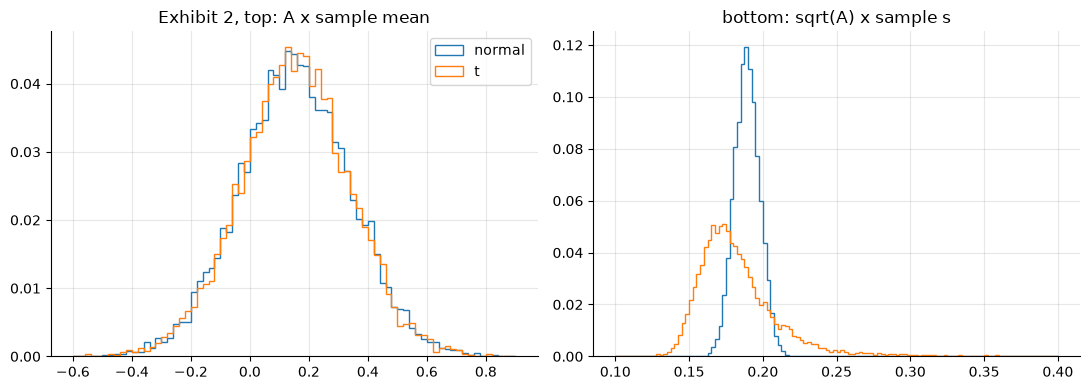

In [3]:
X100 = 100 * R                    # percent, for the optimizer


def nll(p, x=X100):
    # minus the Student-t log-likelihood at (nu, location, scale), returns in percent
    if p[0] <= 0.5 or p[2] <= 0:
        return 1e18
    return -stats.t.logpdf(x, p[0], p[1], p[2]).sum()


def fit_t(x):
    # t.fit as LM15 ran it (on decimal returns), then a tighter Nelder-Mead search in percent
    p0 = np.array(stats.t.fit(x / 100)) * [1, 100, 100]
    res = optimize.minimize(nll, p0, args=(x,), method="Nelder-Mead",
                            options={"xatol": 1e-12, "fatol": 1e-12, "maxiter": 40000, "maxfev": 80000})
    return res.x, -res.fun, p0


p_t, ll_t, p0_t = fit_t(X100)
nu = p_t[0]
show("nu, unrounded (experiment 1 draws with it)", nu, ".6f", "3.065257")

rng = np.random.default_rng([1, SEED])                       # experiment 1
sims = {"normal": Rb + s * rng.standard_normal((10_000, 246))}
sims["t"] = Rb + s * sqrt((nu - 2) / nu) * rng.standard_t(nu, size=(10_000, 246))


def qinv(x, u):
    return np.quantile(x, u, method="inverted_cdf")


def batch_se(x, u):
    qb = np.array([qinv(b, u) for b in x.reshape(20, -1)])
    return qb.std(ddof=0) / sqrt(20)


rows = []
for lab, xs in sims.items():
    am = A * xs.mean(axis=1)
    av = sqrt(A) * xs.std(axis=1, ddof=0)
    rows.append({"model": lab, "sd of annual mean": 100 * am.std(), "sd of volatility": 100 * av.std(),
                 "vol 2.5%": 100 * qinv(av, 0.025), "vol median": 100 * qinv(av, 0.5),
                 "vol 97.5%": 100 * qinv(av, 0.975), "batch SE 97.5%": 100 * batch_se(av, 0.975),
                 "vol above 40%": int((av > 0.40).sum()), "means off the axis": int(((am < -0.6) | (am >= 0.9)).sum())})
tab = pl.DataFrame(rows)
print(tab)
nrm, tt = rows
show("normal: sd of the annual mean", nrm["sd of annual mean"], ".1f", "18.9")
show("normal: its Monte Carlo SE", nrm["sd of annual mean"] / sqrt(20_000), ".2f", "0.13")
show("t: sd of the annual mean", tt["sd of annual mean"], ".1f", "18.7")
show("theory", 100 * sqrt(A) * s * sqrt(A / 246), ".2f", "18.96")
show("normal: sd of the volatility", nrm["sd of volatility"], ".2f", "0.86")
show("normal: its Monte Carlo SE", nrm["sd of volatility"] / sqrt(20_000), ".3f", "0.006")
show("theory", 100 * sqrt(A) * s / sqrt(2 * 246), ".3f", "0.855")
show("t: sd of the volatility, about", tt["sd of volatility"], ".0f", "4")
show("normal 2.5%", nrm["vol 2.5%"], ".1f", "17.3")
show("normal 97.5%", nrm["vol 97.5%"], ".1f", "20.6")
show("t 2.5%", tt["vol 2.5%"], ".1f", "14.6")
show("t 97.5%", tt["vol 97.5%"], ".1f", "26.8")
show("t median", tt["vol median"], ".1f", "17.7")
show("t 97.5% batch SE", tt["batch SE 97.5%"], ".1f", "0.3")
show("t values above 40%", tt["vol above 40%"], "d", "35")
show("t annual means outside -60% to 90%", tt["means off the axis"], "d", "4")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lab, xs in sims.items():
    ax[0].hist(A * xs.mean(axis=1), bins=np.arange(-0.6, 0.9001, 0.02), histtype="step", density=False,
               weights=np.full(10_000, 1e-4), label=lab)
    ax[1].hist(sqrt(A) * xs.std(axis=1, ddof=0), bins=np.arange(0.10, 0.4001, 0.0025), histtype="step",
               weights=np.full(10_000, 1e-4), label=lab)
ax[0].set_title("Exhibit 2, top: A x sample mean"); ax[1].set_title("bottom: sqrt(A) x sample s")
ax[0].legend(); plt.tight_layout(); plt.show()

Experiment 4 repeats the Student-t block 20 more times from its own generator, `default_rng([4, 20261011])`, the runs drawn in turn. The Student-t with $\nu<4$ has no finite fourth moment, so its two standard deviations get the range over runs instead of a Monte Carlo standard error.

In [4]:
rng4 = np.random.default_rng([4, SEED])                      # experiment 4
run_am, run_av = [], []
for _ in range(20):
    xs = Rb + s * sqrt((nu - 2) / nu) * rng4.standard_t(nu, size=(10_000, 246))
    run_am.append(100 * (A * xs.mean(axis=1)).std())
    run_av.append(100 * (sqrt(A) * xs.std(axis=1, ddof=0)).std())
show("experiment 4: annual mean's sd, lowest", min(run_am), ".1f", "18.6")
show("experiment 4: annual mean's sd, highest", max(run_am), ".1f", "19.2")
show("experiment 4: volatility's sd, lowest", min(run_av), ".1f", "3.3")
show("experiment 4: volatility's sd, highest", max(run_av), ".1f", "4.6")

experiment 4: annual mean's sd, lowest: 18.6   [book: 18.6]
experiment 4: annual mean's sd, highest: 19.2   [book: 19.2]
experiment 4: volatility's sd, lowest: 3.3   [book: 3.3]
experiment 4: volatility's sd, highest: 4.6   [book: 4.6]


Example 1: the shrunk mean $\eta\bar R$ with TR23's daily $\bar R/s$ as the model's $\mathrm{SR}$. The minimizer of the mean squared error is checked on a grid.

In [5]:
SR = Rb / s
show("daily SR", SR, ".6f", "0.051727")
for T_, tsr_p, eta_p in ((246, "0.658", "0.397"), (T, "15.65", "0.940")):
    tsr = T_ * SR**2
    show(f"T = {T_}: T SR^2", tsr, ".3f" if T_ == 246 else ".2f", tsr_p)
    show(f"T = {T_}: eta*", tsr / (1 + tsr), ".3f", eta_p)
eta = np.linspace(0, 1.5, 150001)
mse = eta**2 * s**2 / 246 + (eta - 1) ** 2 * Rb**2
print("grid minimizer for one year:", round(eta[mse.argmin()], 4))
show("knowledge check: sqrt(3/246)", sqrt(3 / 246), ".3f", "0.110")

daily SR: 0.051727   [book: 0.051727]
T = 246: T SR^2: 0.658   [book: 0.658]
T = 246: eta*: 0.397   [book: 0.397]
T = 5849: T SR^2: 15.65   [book: 15.65]
T = 5849: eta*: 0.940   [book: 0.940]
grid minimizer for one year: 0.3969
knowledge check: sqrt(3/246): 0.110   [book: 0.110]


## Part 3 — The standard error of a mean

Example 2 and Example 3, then Exhibit 3: TR23's log returns summed over non-overlapping blocks of $m$ sessions from the first return. The annual mean's standard error barely moves with $m$; the annual volatility's grows. Exhibit 5 varies the years of data with TR23's annual mean and volatility held fixed.

s / sqrt(T), % a day: 0.01580   [book: 0.01580]
SE of the annual mean, points: 3.89   [book: 3.89]
years for +-1 point at 95%: 1,381   [book: 1,381]
s_u / s, TR23: 1.0000855   [book: 1.0000855]
23 values: sqrt(23/22): 1.0225   [book: 1.0225]
23 values: s_u, %: 22.706   [book: 22.706]
wrongly scaled by sqrt(A), points: 0.25   [book: 0.25]
shape: (8, 5)
┌─────┬──────┬──────────┬──────────┬─────────────────────┐
│ m   ┆ sums ┆ mean SE  ┆ vol SE   ┆ normal model vol SE │
│ --- ┆ ---  ┆ ---      ┆ ---      ┆ ---                 │
│ i64 ┆ i64  ┆ f64      ┆ f64      ┆ f64                 │
╞═════╪══════╪══════════╪══════════╪═════════════════════╡
│ 1   ┆ 5849 ┆ 3.896346 ┆ 0.338439 ┆ 0.175617            │
│ 2   ┆ 2924 ┆ 4.001535 ┆ 0.501693 ┆ 0.248381            │
│ 5   ┆ 1169 ┆ 4.07909  ┆ 0.649045 ┆ 0.392826            │
│ 10  ┆ 584  ┆ 4.1328   ┆ 0.88685  ┆ 0.555777            │
│ 21  ┆ 278  ┆ 3.911383 ┆ 1.22678  ┆ 0.805536            │
│ 62  ┆ 94   ┆ 3.868698 ┆ 1.566461 ┆ 1.385298           

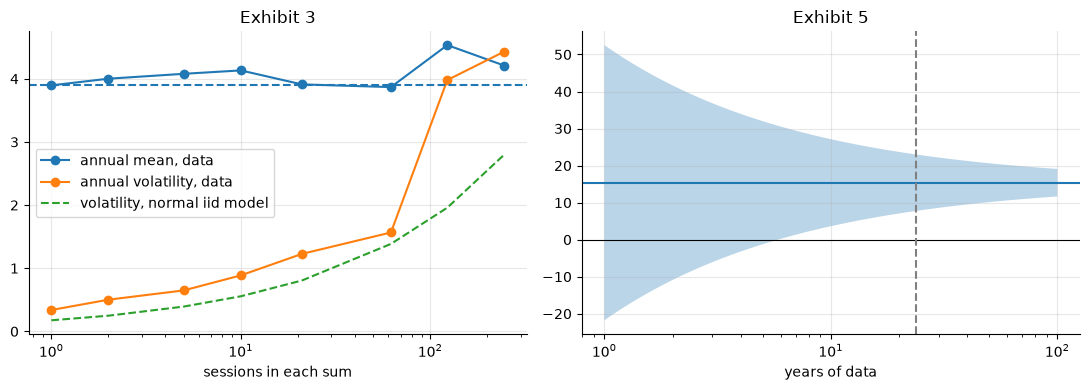

1 years: low: -21.8   [book: -21.8]
1 years: high: 52.5   [book: 52.5]
10 years: low: 3.6   [book: 3.6]
10 years: high: 27.1   [book: 27.1]
100 years: low: 11.7   [book: 11.7]
100 years: high: 19.1   [book: 19.1]


In [6]:
show("s / sqrt(T), % a day", 100 * s / sqrt(T), ".5f", "0.01580")
se_ann = sqrt(A) * s / sqrt(tau)
show("SE of the annual mean, points", 100 * se_ann, ".2f", "3.89")
show("years for +-1 point at 95%", (Z * 100 * sqrt(A) * s) ** 2, ",.0f", "1,381")
show("s_u / s, TR23", su / s, ".7f", "1.0000855")
show("23 values: sqrt(23/22)", sqrt(23 / 22), ".4f", "1.0225")
show("23 values: s_u, %", 100 * ann_log.std(ddof=1), ".3f", "22.706")
show("wrongly scaled by sqrt(A), points", 100 * s / sqrt(T) * sqrt(A), ".2f", "0.25")

_, s_r, _, _ = moments(r)
mer = []
for m in (1, 2, 5, 10, 21, 62, 123, 246):
    nm = T // m
    sums = r[: nm * m].reshape(nm, m).sum(axis=1)
    _, s_m, _, m4_m = moments(sums)
    mer.append({"m": m, "sums": nm, "mean SE": 100 * A / m * s_m / sqrt(nm),
                "vol SE": 100 * sqrt(A / m) * s_m * sqrt((m4_m / s_m**4 - 1) / (4 * nm)),
                "normal model vol SE": 100 * sqrt(A) * s_r / sqrt(2 * nm)})
mer = pl.DataFrame(mer)
print(mer)
show("iid line", 100 * sqrt(A) * s_r / sqrt(tau), ".2f", "3.90")
show("mean SE, lowest", mer["mean SE"].min(), ".2f", "3.87")
show("mean SE, highest", mer["mean SE"].max(), ".2f", "4.53")
show("volatility SE, daily", mer["vol SE"][0], ".2f", "0.34")
show("volatility SE, 246-day sums", mer["vol SE"][-1], ".2f", "4.43")
show("normal model, daily", mer["normal model vol SE"][0], ".2f", "0.18")
show("normal model, 246-day sums", mer["normal model vol SE"][-1], ".2f", "2.80")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogx(mer["m"], mer["mean SE"], "o-", label="annual mean, data")
ax[0].semilogx(mer["m"], mer["vol SE"], "o-", label="annual volatility, data")
ax[0].semilogx(mer["m"], mer["normal model vol SE"], "--", label="volatility, normal iid model")
ax[0].axhline(100 * sqrt(A) * s_r / sqrt(tau), ls="--", color="C0")
ax[0].set_xlabel("sessions in each sum"); ax[0].set_title("Exhibit 3"); ax[0].legend()
yrs = np.geomspace(1, 100, 49)
ax[1].fill_between(yrs, 100 * (A * Rb - Z * sqrt(A) * s / np.sqrt(yrs)), 100 * (A * Rb + Z * sqrt(A) * s / np.sqrt(yrs)),
                   alpha=0.3)
ax[1].axhline(100 * A * Rb); ax[1].axhline(0, color="k", lw=0.8); ax[1].axvline(tau, ls="--", color="grey")
ax[1].set_xscale("log"); ax[1].set_xlabel("years of data"); ax[1].set_title("Exhibit 5")
plt.tight_layout(); plt.show()
for y_, lo_p, hi_p in ((1, "-21.8", "52.5"), (10, "3.6", "27.1"), (100, "11.7", "19.1")):
    h = Z * sqrt(A) * s / sqrt(y_)
    show(f"{y_} years: low", 100 * (A * Rb - h), ".1f", lo_p)
    show(f"{y_} years: high", 100 * (A * Rb + h), ".1f", hi_p)

## Part 4 — Confidence intervals and their coverage

Example 4 with both forms of (20.4), then Exhibit 4: experiment 2 draws 100,000 samples per cell in chunks of 10,000, for each $T$ the normal block and then the $t_3$ block. A $t_3$ day is built from four standard normals and scaled to variance 1.

In [7]:
q = stats.t.ppf(0.975, T - 1)
show("t quantile, 5,848 degrees of freedom", q, ".5f", "1.96037")
show("normal quantile", stats.norm.ppf(0.975), ".5f", "1.95996")
show("interval low, %", 100 * (A * Rb - Z * se_ann), ".1f", "7.8")
show("interval high, %", 100 * (A * Rb + Z * se_ann), ".1f", "23.0")
show("the t form moves the ends by, points", 100 * (q * A * su - Z * A * s) / sqrt(T), ".3f", "0.002")
for kind, half, book_iv in (("1.96 with s", Z * A * s / sqrt(T), "7.7620 to 23.0059"),
                            ("t quantile with s_u", q * A * su / sqrt(T), "7.7599 to 23.0080")):
    show(f"interval, {kind}, %", f"{100 * (A * Rb - half):.4f} to {100 * (A * Rb + half):.4f}", "", book_iv)
    show("  to two decimals", f"{100 * (A * Rb - half):.2f} to {100 * (A * Rb + half):.2f}", "", "7.76 to 23.01")
show("one year: half-width, points", 100 * Z * sqrt(A) * s * sqrt(A / 246), ".1f", "37.2")

rng2 = np.random.default_rng([2, SEED])                      # experiment 2
cov_rows = []
for Tc in (5, 10, 30, 100, 246):
    qc = stats.t.ppf(0.975, Tc - 1)
    row = {"T": Tc, "normal z": 0, "exact": 100 * (2 * stats.t.cdf(Z * sqrt((Tc - 1) / Tc), Tc - 1) - 1),
           "normal t": 0, "t3 z": 0, "t3 t": 0}
    for model in ("normal", "t3"):
        hz = ht = 0
        for _ in range(10):
            if model == "normal":
                xs = rng2.standard_normal((10_000, Tc))
            else:
                zz = rng2.standard_normal((10_000, Tc, 4))
                xs = zz[..., 0] / np.sqrt((zz[..., 1:] ** 2).sum(axis=2) / 3) / sqrt(3)
            mn = xs.mean(axis=1)
            hz += int((np.abs(mn) <= Z * xs.std(axis=1, ddof=0) / sqrt(Tc)).sum())
            ht += int((np.abs(mn) <= qc * xs.std(axis=1, ddof=1) / sqrt(Tc)).sum())
        row[f"{model} z"], row[f"{model} t"] = hz / 1000, ht / 1000
    cov_rows.append(row)
cov = pl.DataFrame(cov_rows).select("T", "normal z", "exact", "normal t", "t3 z", "t3 t")
print(cov.with_columns(pl.exclude("T").round(1)))
book = {5: "84.5 84.6 95.0 86.1 96.4", 10: "90.4 90.4 95.1 91.5 96.0", 30: "93.6 93.6 94.9 94.2 95.6",
        100: "94.6 94.6 95.0 94.9 95.3", 246: "94.8 94.8 95.0 95.0 95.2"}
for row in cov.iter_rows(named=True):
    got = " ".join(f"{row[k]:.1f}" for k in ("normal z", "exact", "normal t", "t3 z", "t3 t"))
    show(f"coverage T = {row['T']}", got, "", book[row["T"]])
show("Monte Carlo SE at 95%, points", 100 * sqrt(0.95 * 0.05 / 100_000), ".2f", "0.07")

t quantile, 5,848 degrees of freedom: 1.96037   [book: 1.96037]
normal quantile: 1.95996   [book: 1.95996]
interval low, %: 7.8   [book: 7.8]
interval high, %: 23.0   [book: 23.0]
the t form moves the ends by, points: 0.002   [book: 0.002]
interval, 1.96 with s, %: 7.7620 to 23.0059   [book: 7.7620 to 23.0059]
  to two decimals: 7.76 to 23.01   [book: 7.76 to 23.01]
interval, t quantile with s_u, %: 7.7599 to 23.0080   [book: 7.7599 to 23.0080]
  to two decimals: 7.76 to 23.01   [book: 7.76 to 23.01]
one year: half-width, points: 37.2   [book: 37.2]
shape: (5, 6)
┌─────┬──────────┬───────┬──────────┬──────┬──────┐
│ T   ┆ normal z ┆ exact ┆ normal t ┆ t3 z ┆ t3 t │
│ --- ┆ ---      ┆ ---   ┆ ---      ┆ ---  ┆ ---  │
│ i64 ┆ f64      ┆ f64   ┆ f64      ┆ f64  ┆ f64  │
╞═════╪══════════╪═══════╪══════════╪══════╪══════╡
│ 5   ┆ 84.5     ┆ 84.6  ┆ 95.0     ┆ 86.1 ┆ 96.4 │
│ 10  ┆ 90.4     ┆ 90.4  ┆ 95.1     ┆ 91.5 ┆ 96.0 │
│ 30  ┆ 93.6     ┆ 93.6  ┆ 94.9     ┆ 94.2 ┆ 95.6 │
│ 100 ┆ 94.6  

## Part 5 — Maximum likelihood

Example 5: the normal MLE is $\bar R$ and $s$ with divisor $T$. The 0050 sample is LM4's: total returns on the 2,902 dates common to 0050 and 00631L, each from the previous common date (two span a fund's split halt). The cash dividend is added on ex-dates, and the previous close is restated per new share on split days (0050 4-for-1 on 2025-06-18; 00631L 22-for-1 on 2026-03-31). Every close is first checked against FinMind's `spread` column.

In [8]:
SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")


def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    bad = df.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)
    expected = (set(div["date"]) if sym == "0050" else set()) | {SPLITS[sym][0]}
    assert not set(bad["date"]) - expected, sorted(set(bad["date"]) - expected)
    return df


def with_actions(sym):
    df = load_raw(sym)
    sd, k = SPLITS[sym]
    d = (div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050"
         else pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64}))
    return (df.join(d, on="date", how="left")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(sd)).then(pl.lit(float(k))).otherwise(pl.lit(1.0)).alias("k"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("k").alias(f"k_{sym}")))


both = with_actions("0050").join(with_actions("00631L"), on="date", how="inner").sort("date")
ret50 = (both.with_columns(((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("k_0050")) - 1)
                           .alias("R"))
             .drop_nulls("R").select("date", "R"))
R50 = ret50["R"].to_numpy()
T50 = len(R50)
mu50, s50, m3_50, m4_50 = moments(R50)
show("0050 returns", T50, ",", "2,902")
show("0050 mean, %", 100 * mu50, ".4f", "0.0871")
show("0050 s, %", 100 * s50, ".4f", "1.2385")
show("0050 SE of the mean, % (LM4's)", 100 * s50 / sqrt(T50), ".4f", "0.0230")
show("TR23 s_u, %", 100 * su, ".4f", "1.2085")

0050 returns: 2,902   [book: 2,902]
0050 mean, %: 0.0871   [book: 0.0871]
0050 s, %: 1.2385   [book: 1.2385]
0050 SE of the mean, % (LM4's): 0.0230   [book: 0.0230]
TR23 s_u, %: 1.2085   [book: 1.2085]


Example 6 and Exhibit 6: the Student-t fit of Part 2 and its standard errors from the observed information. That information is a central-difference Hessian of $-\ell$, checked at two step sizes. The cells then give the fit's standard deviation by (20.8) and the fits by price-limit regime.

In [9]:
def hessian(f, p, h):
    # central-difference Hessian of f at p with steps h
    k = len(p)
    H = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            a, b = np.eye(k)[i] * h[i], np.eye(k)[j] * h[j]
            H[i, j] = (f(p + a + b) - f(p + a - b) - f(p - a + b) + f(p - a - b)) / (4 * h[i] * h[j])
    return H


def fit_with_se(x):
    p, ll, p0 = fit_t(x)
    covs = [np.linalg.inv(hessian(lambda q_: nll(q_, x), p, np.array(h))) for h in ([1e-4, 1e-5, 1e-5], [1e-3, 1e-4, 1e-4])]
    se0, se1 = np.sqrt(np.diag(covs[0])), np.sqrt(np.diag(covs[1]))
    assert np.all(np.abs(se0 / se1 - 1) < 1e-4), (se0, se1)        # the two step sizes agree
    return p, covs[0], ll, p0


p_t, cov_t, ll_t, p0_t = fit_with_se(X100)
se_t = np.sqrt(np.diag(cov_t))
nu, loc, scale = p_t
show("t.fit's nu", p0_t[0], ".5f", "3.06522")
show("refined nu", nu, ".5f", "3.06526")
show("nu", nu, ".3f", "3.065"); show("SE", se_t[0], ".3f", "0.144")
show("location, %", loc, ".4f", "0.0997"); show("SE", se_t[1], ".4f", "0.0124")
show("scale, %", scale, ".4f", "0.7761"); show("SE", se_t[2], ".4f", "0.0138")
ll_n = stats.norm.logpdf(X100, X100.mean(), X100.std(ddof=0)).sum()
show("log-likelihood gain over the normal", ll_t - ll_n, ".1f", "561.8")
g = np.array([scale * 0.5 * sqrt((nu - 2) / nu) * (-2 / (nu - 2) ** 2), 0.0, sqrt(nu / (nu - 2))])
show("fit's standard deviation, %", scale * sqrt(nu / (nu - 2)), ".3f", "1.317")
show("its SE", sqrt(g @ cov_t @ g), ".3f", "0.045")
cor = cov_t / np.outer(se_t, se_t)
show("correlation of nu and scale", cor[0, 2], ".2f", "0.68")

pre = (pl.Series(dates).str.to_date() < pl.Series(["2015-06-01"]).str.to_date()[0]).to_numpy()
regime = {}
for name, msk in (("7% limit, to 29 May 2015", pre), ("10% limit, from 1 June 2015", ~pre)):
    pp, cc, _, _ = fit_with_se(X100[msk])
    regime[name] = (int(msk.sum()), pp[0], sqrt(cc[0, 0]))
    print(f"{name}: {msk.sum()} returns, nu {pp[0]:.3f} (SE {sqrt(cc[0, 0]):.3f})")
(n1, nu1, se1), (n2, nu2, se2) = regime.values()
show("returns before", n1, ",", "3,077"); show("nu", nu1, ".3f", "2.990"); show("SE", se1, ".3f", "0.195")
show("returns after", n2, ",", "2,772"); show("nu", nu2, ".3f", "3.237"); show("SE", se2, ".3f", "0.223")

t.fit's nu: 3.06522   [book: 3.06522]
refined nu: 3.06526   [book: 3.06526]
nu: 3.065   [book: 3.065]
SE: 0.144   [book: 0.144]
location, %: 0.0997   [book: 0.0997]
SE: 0.0124   [book: 0.0124]
scale, %: 0.7761   [book: 0.7761]
SE: 0.0138   [book: 0.0138]
log-likelihood gain over the normal: 561.8   [book: 561.8]
fit's standard deviation, %: 1.317   [book: 1.317]
its SE: 0.045   [book: 0.045]
correlation of nu and scale: 0.68   [book: 0.68]
7% limit, to 29 May 2015: 3077 returns, nu 2.990 (SE 0.195)
10% limit, from 1 June 2015: 2772 returns, nu 3.237 (SE 0.223)
returns before: 3,077   [book: 3,077]
nu: 2.990   [book: 2.990]
SE: 0.195   [book: 0.195]
returns after: 2,772   [book: 2,772]
nu: 3.237   [book: 3.237]
SE: 0.223   [book: 0.223]


Exhibit 7: at each $\nu$ the location and scale are re-maximized. The points where the profile falls $1.96^2/2$ below its maximum give the likelihood's interval; the parabola of the observed information gives $\hat\nu\pm1.96$ SE.

profile interval, low: 2.80   [book: 2.80]
high: 3.37   [book: 3.37]
Wald interval, low: 2.78   [book: 2.78]
high: 3.35   [book: 3.35]


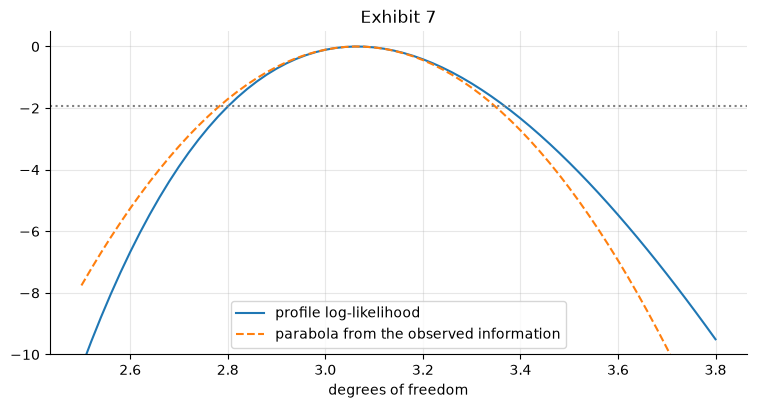

In [10]:
def profile(v):
    res = optimize.minimize(lambda q_: nll(np.array([v, q_[0], q_[1]])), np.array([loc, scale]),
                            method="Nelder-Mead", options={"xatol": 1e-11, "fatol": 1e-11, "maxiter": 20000})
    return -res.fun - ll_t


drop = Z**2 / 2
lo_pl = optimize.brentq(lambda v: profile(v) + drop, 2.5, nu)
hi_pl = optimize.brentq(lambda v: profile(v) + drop, nu, 4.0)
show("profile interval, low", lo_pl, ".2f", "2.80"); show("high", hi_pl, ".2f", "3.37")
show("Wald interval, low", nu - Z * se_t[0], ".2f", "2.78"); show("high", nu + Z * se_t[0], ".2f", "3.35")
grid = np.arange(2.5, 3.8001, 0.02)
plt.plot(grid, [profile(v) for v in grid], label="profile log-likelihood")
plt.plot(grid, -(grid - nu) ** 2 / (2 * se_t[0] ** 2), "--", label="parabola from the observed information")
plt.axhline(-drop, ls=":", color="grey"); plt.ylim(-10, 0.5); plt.xlabel("degrees of freedom")
plt.title("Exhibit 7"); plt.legend(); plt.show()

## Part 6 — Information and the delta method

Example 7, Example 8 (with the $\chi^2_{22}$ interval of a normal model for the 23 annual values) and Example 9, collected in Exhibit 8. The plug-in standard errors use the sample's skewness and kurtosis; "normal" uses 0 and 3; "mean only" keeps the first term of (20.9).

The volatility's, the Kelly fraction's and the Sharpe ratio's standard errors need a finite fourth moment, which the Student-t fit ($\nu=3.065$) lacks, so they are nominal. Exhibit 3's volatility errors and the regimes' 0.026 and 0.035 rest on the sample kurtosis too.

In [11]:
show("SE(mu-hat), %", 100 * s / sqrt(T), ".4f", "0.0158")
show("SE(sigma-hat), %", 100 * s / sqrt(2 * T), ".4f", "0.0112")
# efficiency inside one model: in the fitted Student-t, R-bar's SE is the fit's standard deviation over sqrt(T)
se_rb_t = scale * sqrt(nu / (nu - 2)) / sqrt(T)
show("R-bar's SE inside the Student-t model, %", se_rb_t, ".4f", "0.0172")
show("location SE / R-bar's SE, same model", se_t[1] / se_rb_t, ".2f", "0.72")

vol = sqrt(A) * s
show("SE of the annual volatility, plug-in", 100 * vol * sqrt((kurt - 1) / (4 * T)), ".3f", "0.334")
show("SE of the annual volatility, normal", 100 * vol / sqrt(2 * T), ".3f", "0.175")
sa = ann_log.std(ddof=0)
se_a = sa / sqrt(2 * 23)
show("23 values: SE, points", 100 * se_a, ".2f", "3.27")
show("interval low", 100 * (sa - Z * se_a), ".1f", "15.8"); show("high", 100 * (sa + Z * se_a), ".1f", "28.6")
r_w = r[np.array([d <= "2025-12-31" for d in dates])]
_, s_rw, _, m4_rw = moments(r_w)
show("LM17's daily-based 18.563%", 100 * sqrt(246) * s_rw, ".3f", "18.563")
show("its log returns, 2003-2025", len(r_w), ",", "5,664")
show("their kurtosis", m4_rw / s_rw**4, ".2f", "8.55")
show("its plug-in SE", 100 * sqrt(246) * s_rw * sqrt((m4_rw / s_rw**4 - 1) / (4 * len(r_w))), ".2f", "0.34")
show("gap in standard errors", (sa - sqrt(246) * s_rw) / se_a, ".1f", "1.1")
c_lo, c_hi = stats.chi2.ppf([0.025, 0.975], 22)
show("chi2_22 2.5%", c_lo, ".2f", "10.98"); show("97.5%", c_hi, ".2f", "36.78")
show("chi2 interval for sigma, low", 100 * sa * sqrt(23 / c_hi), ".1f", "17.6")
show("high", 100 * sa * sqrt(23 / c_lo), ".1f", "32.1")
_, sx1, _, m4x1 = moments(R[pre]); _, sx2, _, m4x2 = moments(R[~pre])
show("s before 1 June 2015, %", 100 * sx1, ".3f", "1.257")
show("its SE", 100 * sx1 * sqrt((m4x1 / sx1**4 - 1) / (4 * pre.sum())), ".3f", "0.026")
show("s from 1 June 2015, %", 100 * sx2, ".3f", "1.152")
show("its SE", 100 * sx2 * sqrt((m4x2 / sx2**4 - 1) / (4 * (~pre).sum())), ".3f", "0.035")


def se_kelly(m, sd, m3_, m4_, n):        # (20.9)
    return sqrt((1 / sd**2 - 2 * m * m3_ / sd**6 + m**2 * (m4_ - sd**4) / sd**8) / n)


def se_sharpe(m, sd, m3_, m4_, n):       # (20.9)
    sr_ = m / sd
    return sqrt((1 - sr_ * m3_ / sd**3 + sr_**2 * (m4_ / sd**4 - 1) / 4) / n)


rows = []
for name, m, sd, m3_, m4_, n in (("TR23", Rb, s, m3, m4, T), ("0050", mu50, s50, m3_50, m4_50, T50)):
    f = m / sd**2
    se = se_kelly(m, sd, m3_, m4_, n)
    rows.append({"sample": name, "f-hat": f, "SE mean only": 1 / (sd * sqrt(n)),
                 "SE normal": se_kelly(m, sd, 0.0, 3 * sd**4, n), "SE plug-in": se,
                 "low": f - Z * se, "high": f + Z * se, "skewness": m3_ / sd**3, "kurtosis": m4_ / sd**4})
delta = pl.DataFrame(rows)
print(delta)
k_tr, k_50 = rows
show("TR23 f-hat", k_tr["f-hat"], ".2f", "4.28")
show("mean only", k_tr["SE mean only"], ".3f", "1.082"); show("normal", k_tr["SE normal"], ".3f", "1.085")
show("plug-in", k_tr["SE plug-in"], ".3f", "1.111")
show("interval", f"{k_tr['low']:.2f} to {k_tr['high']:.2f}", "", "2.10 to 6.46")
show("0050 f", k_50["f-hat"], ".2f", "5.68")
show("mean only", k_50["SE mean only"], ".3f", "1.499"); show("normal", k_50["SE normal"], ".3f", "1.506")
show("plug-in", k_50["SE plug-in"], ".3f", "1.532")
show("interval", f"{k_50['low']:.2f} to {k_50['high']:.2f}", "", "2.68 to 8.68")
f50, sm50 = k_50["f-hat"], k_50["SE mean only"]
show("LM4's quadratic band", f"{f50 - Z * sm50:.2f} to {f50 + Z * sm50:.2f}", "", "2.74 to 8.62")
show("0050 skewness", k_50["skewness"], ".2f", "0.04"); show("kurtosis", k_50["kurtosis"], ".2f", "11.12")
sr = Rb / s
se_s = se_sharpe(Rb, s, m3, m4, T)
show("daily SR", sr, ".4f", "0.0517"); show("SE plug-in", se_s, ".4f", "0.0132")
show("SE normal", sqrt((1 + sr**2 / 2) / T), ".4f", "0.0131")
show("annual SR", sqrt(A) * sr, ".2f", "0.81"); show("SE plug-in", sqrt(A) * se_s, ".3f", "0.207")
show("SE normal", sqrt(A) * sqrt((1 + sr**2 / 2) / T), ".3f", "0.205")
show("interval", f"{sqrt(A) * (sr - Z * se_s):.2f} to {sqrt(A) * (sr + Z * se_s):.2f}", "", "0.40 to 1.22")
show("1/sqrt(tau)", 1 / sqrt(tau), ".3f", "0.205")

SE(mu-hat), %: 0.0158   [book: 0.0158]
SE(sigma-hat), %: 0.0112   [book: 0.0112]
R-bar's SE inside the Student-t model, %: 0.0172   [book: 0.0172]
location SE / R-bar's SE, same model: 0.72   [book: 0.72]
SE of the annual volatility, plug-in: 0.334   [book: 0.334]
SE of the annual volatility, normal: 0.175   [book: 0.175]
23 values: SE, points: 3.27   [book: 3.27]
interval low: 15.8   [book: 15.8]
high: 28.6   [book: 28.6]
LM17's daily-based 18.563%: 18.563   [book: 18.563]
its log returns, 2003-2025: 5,664   [book: 5,664]
their kurtosis: 8.55   [book: 8.55]
its plug-in SE: 0.34   [book: 0.34]
gap in standard errors: 1.1   [book: 1.1]
chi2_22 2.5%: 10.98   [book: 10.98]
97.5%: 36.78   [book: 36.78]
chi2 interval for sigma, low: 17.6   [book: 17.6]
high: 32.1   [book: 32.1]
s before 1 June 2015, %: 1.257   [book: 1.257]
its SE: 0.026   [book: 0.026]
s from 1 June 2015, %: 1.152   [book: 1.152]
its SE: 0.035   [book: 0.035]
shape: (2, 9)
┌────────┬──────────┬──────────────┬───────────┬──

## Part 7 — The Hill estimator

Example 10 and Exhibit 9: losses $-R$ at or beyond a threshold $x_0$, counted with the guard, $\hat\alpha=k/\sum\ln(x_i/x_0)$ and its standard error $\hat\alpha/\sqrt k$, (20.10). The estimate rises from 2% to 4%, then wanders once fewer than 45 losses remain.

x0 = 0.02: k: 252   [book: 252]
alpha: 2.49   [book: 2.49]
SE: 0.16   [book: 0.16]
x0 = 0.03: k: 108   [book: 108]
alpha: 3.63   [book: 3.63]
SE: 0.35   [book: 0.35]
x0 = 0.04: k: 44   [book: 44]
alpha: 4.93   [book: 4.93]
SE: 0.74   [book: 0.74]
x0 = 0.05: k: 15   [book: 15]
alpha: 4.76   [book: 4.76]
SE: 1.23   [book: 1.23]
interval at 3%: 2.9 to 4.3   [book: 2.9 to 4.3]
width of the interval at 5%: 4.8   [book: 4.8]
k < 45 from x0 = 3.90%: the estimate wanders between 4.13 and 6.88


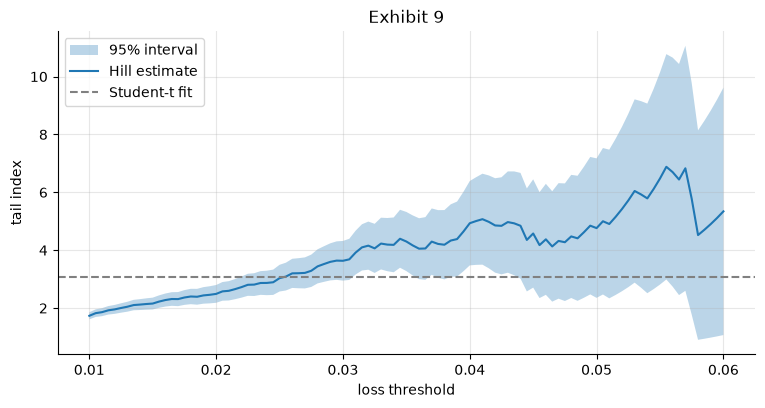

In [12]:
def hill(x0):
    k = count_le(x0)
    xs = -R[R <= -float(x0) + EPS]
    a = k / np.log(xs / float(x0)).sum()
    return k, a, a / sqrt(k)


for x0, k_p, a_p, e_p in (("0.02", "252", "2.49", "0.16"), ("0.03", "108", "3.63", "0.35"),
                          ("0.04", "44", "4.93", "0.74"), ("0.05", "15", "4.76", "1.23")):
    k, a, e = hill(x0)
    show(f"x0 = {x0}: k", k, "d", k_p); show("alpha", a, ".2f", a_p); show("SE", e, ".2f", e_p)
k, a, e = hill("0.03")
show("interval at 3%", f"{a - Z * e:.1f} to {a + Z * e:.1f}", "", "2.9 to 4.3")
show("width of the interval at 5%", 2 * Z * hill("0.05")[2], ".1f", "4.8")

x0s = np.round(np.arange(0.01, 0.06001, 0.0005), 4)
est = []
for x0 in x0s:
    xs = -R[R <= -x0 + EPS]
    a = len(xs) / np.log(xs / x0).sum()
    est.append((a, a / sqrt(len(xs))))
est = np.array(est)
ks = np.array([int((R <= -x0 + EPS).sum()) for x0 in x0s])
few = est[ks < 45, 0]
print(f"k < 45 from x0 = {x0s[ks < 45][0]:.2%}: the estimate wanders between {few.min():.2f} and {few.max():.2f}")
plt.fill_between(x0s, est[:, 0] - Z * est[:, 1], est[:, 0] + Z * est[:, 1], alpha=0.3, label="95% interval")
plt.plot(x0s, est[:, 0], label="Hill estimate")
plt.axhline(nu, ls="--", color="grey", label="Student-t fit")
plt.xlabel("loss threshold"); plt.ylabel("tail index"); plt.title("Exhibit 9"); plt.legend(); plt.show()

## Part 8 — Practice problems 6 to 11

**Problem 6.** LM16's U28 sample: the 28 leaf sector price indices and the TAIEX price index, returns between consecutive TAIEX-calendar dates, 2008-12-02 to 2026-10-08, $T=4{,}382$. FinMind copied some sector closes from another date or series; the book replaces each listed close by its official 13:30:00 value. On the free plan that value is missing, the cell drops the close instead (never estimating it), the sample shrinks, and the numbers differ from the module's.

In [13]:
FIRST_CLOSE, LAST_CLOSE = "2008-12-01", "2026-10-08"
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
sraw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
series = [c_ for c_ in sraw.columns if c_ != "date"]
fixed = sraw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g_ = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g_, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
FULL_DATA = int(rep["close_1330"].is_not_null().sum()) == rep.height
U28 = [c_ for c_ in series if c_ not in ("TAIEX", *AGGREGATES)]
cl = fixed.filter(pl.col("date").is_between(pl.lit(FIRST_CLOSE), pl.lit(LAST_CLOSE))).sort("date")
uret = cl.with_columns([(pl.col(c_) / pl.col(c_).shift(1) - 1).alias(c_) for c_ in series]).slice(1)
usmp = uret.filter(pl.all_horizontal([pl.col(c_).is_not_null() for c_ in ["TAIEX", *U28]]))
x1, x2 = usmp["Semiconductor"].to_numpy(), usmp["FinancialInsurance"].to_numpy()
TU = len(x1)
z1, z2 = (x1 - x1.mean()) / x1.std(ddof=0), (x2 - x2.mean()) / x2.std(ddof=0)
rho = (z1 * z2).mean()
L = z1 * z2 - rho / 2 * (z1**2 + z2**2)
se_n, se_p = (1 - rho**2) / sqrt(TU), L.std(ddof=0) / sqrt(TU)
print(f"repairs complete: {FULL_DATA}; T = {TU}")
got = (f"T {TU}, rho {rho:.4f}, normal SE {se_n:.4f} ({rho - Z * se_n:.3f} to {rho + Z * se_n:.3f}), "
       f"plug-in SE {se_p:.4f} ({rho - Z * se_p:.3f} to {rho + Z * se_p:.3f}), ratio {se_p / se_n:.2f}")
book = "T 4382, rho 0.5749, normal SE 0.0101 (0.555 to 0.595), plug-in SE 0.0153 (0.545 to 0.605), ratio 1.51"
print(got); print("book:", book)
if FULL_DATA:
    assert got == book
else:
    print("(differs: closes were dropped)")

repairs complete: True; T = 4382
T 4382, rho 0.5749, normal SE 0.0101 (0.555 to 0.595), plug-in SE 0.0153 (0.545 to 0.605), ratio 1.51
book: T 4382, rho 0.5749, normal SE 0.0101 (0.555 to 0.595), plug-in SE 0.0153 (0.545 to 0.605), ratio 1.51


**Problem 7.** The regime fits of Part 5, and the difference in $\nu$ with its standard error, the two fits taken as independent. **Problem 8.** Monthly counts of $\lvert R\rvert\ge3\%$ in the 286 calendar months with a session, zero counts included, with the Poisson MLE and its information-based standard error. **Problem 9.** The up-day frequency $\hat\theta$ with its interval.

In [14]:
show("P7: difference in nu", nu2 - nu1, ".3f", "0.247")
show("P7: its SE", sqrt(se1**2 + se2**2), ".3f", "0.296")
show("P7: in standard errors", (nu2 - nu1) / sqrt(se1**2 + se2**2), ".1f", "0.8")

big = pl.DataFrame({"month": [d[:7] for d in dates], "big": (R <= -0.03 + EPS) | (R >= 0.03 - EPS)})
counts = big.group_by("month").agg(pl.col("big").sum().alias("n")).sort("month")["n"].to_numpy().astype(float)
exact_big = sum(1 for q_ in RF if q_ <= Fraction("-0.03") or q_ >= Fraction("0.03"))
assert counts.sum() == exact_big
lam = counts.mean()
show("P8: months", len(counts), "d", "286"); show("P8: days", int(counts.sum()), "d", "175")
show("P8: lambda-hat", lam, ".5f", "0.61189"); show("P8: Poisson SE", sqrt(lam / len(counts)), ".5f", "0.04625")
show("P8: counts' SE", counts.std(ddof=0) / sqrt(len(counts)), ".4f", "0.0803")
show("P8: variance / mean", counts.var(ddof=0) / lam, ".4f", "3.0167")
show("P8: ratio", counts.std(ddof=0) / sqrt(lam), ".3f", "1.737")

up = int((R > EPS).sum())
assert up == sum(1 for q_ in RF if q_ > 0)
th = up / T
se_th = sqrt(th * (1 - th) / T)
show("P9: up days", up, ",", "3,205"); show("P9: theta-hat", th, ".4f", "0.5480"); show("P9: SE", se_th, ".4f", "0.0065")
show("P9: interval", f"{th - Z * se_th:.3f} to {th + Z * se_th:.3f}", "", "0.535 to 0.561")

P7: difference in nu: 0.247   [book: 0.247]
P7: its SE: 0.296   [book: 0.296]
P7: in standard errors: 0.8   [book: 0.8]
P8: months: 286   [book: 286]
P8: days: 175   [book: 175]
P8: lambda-hat: 0.61189   [book: 0.61189]
P8: Poisson SE: 0.04625   [book: 0.04625]
P8: counts' SE: 0.0803   [book: 0.0803]
P8: variance / mean: 3.0167   [book: 3.0167]
P8: ratio: 1.737   [book: 1.737]
P9: up days: 3,205   [book: 3,205]
P9: theta-hat: 0.5480   [book: 0.5480]
P9: SE: 0.0065   [book: 0.0065]
P9: interval: 0.535 to 0.561   [book: 0.535 to 0.561]


**Problem 10.** Hill at 2% and 4% with their intervals. **Problem 11.** Experiment 3: 20,000 normal samples of $T=5$, coverage of $\bar X\pm1.96\,s/\sqrt5$ (divisor 5) and of the $t_4$ interval with $s_{\mathrm u}$, with Monte Carlo standard errors and the exact value. The question is whether the first interval's simulated coverage differs from its exact coverage by more than chance.

In [15]:
for x0, iv in (("0.02", "2.2 to 2.8"), ("0.04", "3.5 to 6.4")):
    k, a, e = hill(x0)
    show(f"P10: interval at {x0}", f"{a - Z * e:.1f} to {a + Z * e:.1f}", "", iv)

rng3 = np.random.default_rng([3, SEED])                      # experiment 3
x3 = rng3.standard_normal((20000, 5))
cz = (np.abs(x3.mean(axis=1)) <= Z * x3.std(axis=1, ddof=0) / sqrt(5)).mean()
ct = (np.abs(x3.mean(axis=1)) <= stats.t.ppf(0.975, 4) * x3.std(axis=1, ddof=1) / sqrt(5)).mean()
exact5 = 2 * stats.t.cdf(Z * sqrt(4 / 5), 4) - 1
show("P11: coverage, 1.96 with s, %", 100 * cz, ".1f", "84.3"); show("MC SE", 100 * sqrt(cz * (1 - cz) / 20000), ".2f", "0.26")
show("P11: coverage, t_4 with s_u, %", 100 * ct, ".1f", "94.8"); show("MC SE", 100 * sqrt(ct * (1 - ct) / 20000), ".2f", "0.16")
show("P11: exact, %", 100 * exact5, ".1f", "84.6")
show("P11: before rounding, exact against simulated, %", f"{100 * exact5:.2f} against {100 * cz:.2f}", "",
     "84.55 against 84.32")
show("P11: the gap, points", 100 * (exact5 - cz), ".2f", "0.23")
print(f"the gap in Monte Carlo standard errors: {(exact5 - cz) / sqrt(cz * (1 - cz) / 20000):.2f}")
show("P11: t_4 coverage before rounding, %", 100 * ct, ".2f", "94.77")
print(f"its distance from 95% in Monte Carlo standard errors: {(0.95 - ct) / sqrt(ct * (1 - ct) / 20000):.2f}")

P10: interval at 0.02: 2.2 to 2.8   [book: 2.2 to 2.8]
P10: interval at 0.04: 3.5 to 6.4   [book: 3.5 to 6.4]
P11: coverage, 1.96 with s, %: 84.3   [book: 84.3]
MC SE: 0.26   [book: 0.26]
P11: coverage, t_4 with s_u, %: 94.8   [book: 94.8]
MC SE: 0.16   [book: 0.16]
P11: exact, %: 84.6   [book: 84.6]
P11: before rounding, exact against simulated, %: 84.55 against 84.32   [book: 84.55 against 84.32]
P11: the gap, points: 0.23   [book: 0.23]
the gap in Monte Carlo standard errors: 0.91
P11: t_4 coverage before rounding, %: 94.77   [book: 94.77]
its distance from 95% in Monte Carlo standard errors: 1.46


### Extension: the Kelly fraction in each limit regime

The daily price limit was 7% until 29 May 2015 and 10% from 1 June 2015. Compute the plug-in Kelly fraction $\hat f=\bar R/s^2$ of each regime with its delta-method standard error (20.9) and 95% interval, using the regime's own mean, $s$, skewness and kurtosis. Do the two intervals overlap?

Then ask what the comparison assumes: each regime's days iid, a finite fourth moment, and nothing learned from the comparison itself. A regime split is a stability check, not a test (tests are LM21's subject).

In [16]:
for name, msk in (("to 29 May 2015", pre), ("from 1 June 2015", ~pre)):
    x = R[msk]
    m, sd, m3_, m4_ = moments(x)
    print(f"{name}: {len(x)} returns, mean {100 * m:.4f}%, s {100 * sd:.4f}%")
# your code: f-hat = m / sd**2 and se_kelly(m, sd, m3_, m4_, len(x)) for each regime, then the intervals

to 29 May 2015: 3077 returns, mean 0.0464%, s 1.2570%
from 1 June 2015: 2772 returns, mean 0.0804%, s 1.1517%
